# 🚀 04 - Hyperparameter Tuning, Threshold Optimization & Ensemble Methods

Nâng cao hiệu năng mô hình theo các yêu cầu mở rộng của đề bài:
- **1. Tinh chỉnh siêu tham số (Hyperparameter Tuning)**: Tối ưu C, learning_rate, alpha trên tập Validation
- **2. Tối ưu hóa ngưỡng quyết định (Threshold Tuning)**: Dò ngưỡng xác suất thỏa mãn ràng buộc Recall >= 0.85
- **3. Phương pháp kết hợp mô hình (Ensemble Methods)**: Xây dựng SpamVotingEnsemble, Random Forest / Boosting
- **4. So sánh hiệu năng trước và sau tối ưu & Lựa chọn mô hình vô địch**


In [1]:
import sys
from pathlib import Path

# Đảm bảo nạp đúng mã nguồn từ thư mục gốc của đồ án
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.config import NOTEBOOK_SAVED_MODELS_DIR
from src.models.classifiers import (
    LogisticRegressionFromScratch,
    LinearSVMFromScratch,
    NaiveBayesClassifier,
)
from src.models.tuning import (
    tune_model_hyperparameters,
    ThresholdOptimizerScratch,
    ModelSelectionWorkflow,
)
from src.models.ensemble import SpamVotingEnsemble
from src.models.persistence import save_spam_pipeline

# Nạp ma trận đặc trưng từ data/processed/
print('Nạp ma trận đặc trưng từ data/processed/...')
X_train = sp.load_npz(PROJECT_ROOT / 'data/processed/X_train.npz')
y_train = np.load(PROJECT_ROOT / 'data/processed/y_train.npy')
X_val = sp.load_npz(PROJECT_ROOT / 'data/processed/X_val.npz')
y_val = np.load(PROJECT_ROOT / 'data/processed/y_val.npy')
X_test = sp.load_npz(PROJECT_ROOT / 'data/processed/X_test.npz')
y_test = np.load(PROJECT_ROOT / 'data/processed/y_test.npy')

df_splits_info = pd.DataFrame([
    {
        "Tập dữ liệu": "Tập huấn luyện (Train)",
        "Kích thước (Shape)": str(X_train.shape),
        "Tổng số mẫu": f"{X_train.shape[0]:,}",
        "Số mẫu Spam": f"{int(np.sum(y_train == 1)):,}",
        "Tỷ lệ Spam (%)": f"{(np.sum(y_train == 1) / len(y_train) * 100):.2f}%"
    },
    {
        "Tập dữ liệu": "Tập kiểm định (Validation)",
        "Kích thước (Shape)": str(X_val.shape),
        "Tổng số mẫu": f"{X_val.shape[0]:,}",
        "Số mẫu Spam": f"{int(np.sum(y_val == 1)):,}",
        "Tỷ lệ Spam (%)": f"{(np.sum(y_val == 1) / len(y_val) * 100):.2f}%"
    },
    {
        "Tập dữ liệu": "Tập kiểm thử (Test)",
        "Kích thước (Shape)": str(X_test.shape),
        "Tổng số mẫu": f"{X_test.shape[0]:,}",
        "Số mẫu Spam": f"{int(np.sum(y_test == 1)):,}",
        "Tỷ lệ Spam (%)": f"{(np.sum(y_test == 1) / len(y_test) * 100):.2f}%"
    }
])
display(df_splits_info)


Nạp ma trận đặc trưng từ data/processed/...


,Tập dữ liệu,Kích thước (Shape),Tổng số mẫu,Số mẫu Spam,Tỷ lệ Spam (%)
0,Tập huấn luyện (Train),"(23223, 4318)","23,223","9,914",42.69%
1,Tập kiểm định (Validation),"(2903, 4318)","2,903","1,239",42.68%
2,Tập kiểm thử (Test),"(2902, 4318)","2,902","1,239",42.69%


## 1. Tinh chỉnh siêu tham số (Hyperparameter Tuning)


In [2]:
# 1. Tinh chỉnh Naive Bayes (alpha)
print('Đang dò tìm siêu tham số tối ưu...')
best_nb, best_nb_params, best_nb_f1 = tune_model_hyperparameters(
    model_name='naive_bayes',
    model_class=lambda **kw: NaiveBayesClassifier(kind='complement', **kw),
    param_grid={'alpha': [0.1, 0.5, 1.0, 2.0]},
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    scoring_metric='f1',
)

# 2. Tinh chỉnh Logistic Regression (C, learning_rate)
best_lr, best_lr_params, best_lr_f1 = tune_model_hyperparameters(
    model_name='logistic_regression',
    model_class=lambda **kw: LogisticRegressionFromScratch(max_iter=100, class_weight='balanced', **kw),
    param_grid={'C': [0.5, 1.0, 5.0], 'learning_rate': [0.5, 1.0]},
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    scoring_metric='f1',
)

# 3. Tinh chỉnh Linear SVM (C, learning_rate)
best_svm, best_svm_params, best_svm_f1 = tune_model_hyperparameters(
    model_name='svm',
    model_class=lambda **kw: LinearSVMFromScratch(max_iter=80, class_weight='balanced', **kw),
    param_grid={'C': [0.5, 1.0, 5.0], 'learning_rate': [0.2, 0.5]},
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    scoring_metric='f1',
)

# Bảng tổng kết kết quả dò siêu tham số dạng DataFrame
df_tuning_summary = pd.DataFrame([
    {
        "Mô hình": "Complement Naive Bayes",
        "Không gian dò (Grid)": "alpha in [0.1, 0.5, 1.0, 2.0]",
        "Siêu tham số tối ưu (Best Params)": str(best_nb_params),
        "Mục tiêu tối ưu": "F1-Score",
        "Validation F1": round(best_nb_f1, 4),
    },
    {
        "Mô hình": "Logistic Regression",
        "Không gian dò (Grid)": "C in [0.5, 1.0, 5.0], lr in [0.5, 1.0], max_iter=100",
        "Siêu tham số tối ưu (Best Params)": str(best_lr_params),
        "Mục tiêu tối ưu": "F1-Score",
        "Validation F1": round(best_lr_f1, 4),
    },
    {
        "Mô hình": "Linear SVM",
        "Không gian dò (Grid)": "C in [0.5, 1.0, 5.0], lr in [0.2, 0.5], max_iter=80",
        "Siêu tham số tối ưu (Best Params)": str(best_svm_params),
        "Mục tiêu tối ưu": "F1-Score",
        "Validation F1": round(best_svm_f1, 4),
    },
])
display(df_tuning_summary)


Đang dò tìm siêu tham số tối ưu...


,Mô hình,Không gian dò (Grid),Siêu tham số tối ưu (Best Params),Mục tiêu tối ưu,Validation F1
0,Complement Naive Bayes,"alpha in [0.1, 0.5, 1.0, 2.0]",{'alpha': 1.0},F1-Score,-1.1965
1,Logistic Regression,"C in [0.5, 1.0, 5.0], lr in [0.5, 1.0], max_it...","{'C': 0.5, 'learning_rate': 1.0}",F1-Score,-1.1226
2,Linear SVM,"C in [0.5, 1.0, 5.0], lr in [0.2, 0.5], max_it...","{'C': 0.5, 'learning_rate': 0.2}",F1-Score,-1.0833


## 2. Tối ưu hóa ngưỡng phân loại (Threshold Tuning với ràng buộc Recall >= 0.85)


,Chỉ tiêu tối ưu ngưỡng,Giá trị
0,Mô hình áp dụng,Logistic Regression (Tuned)
1,Ngưỡng tối ưu (Best Threshold),0.4400
2,Val Recall đạt được,0.8539 (Mục tiêu >= 0.85: True)
3,Val Precision đạt được,0.5510
4,Val F1-Score,0.6698
5,Val F-Beta (Beta=2.0),0.7693


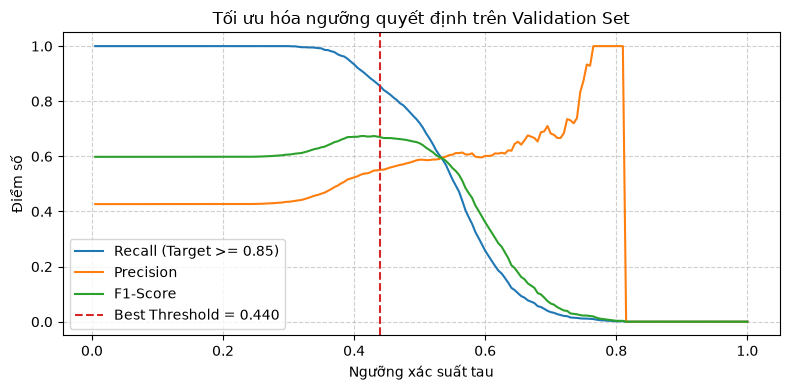

In [3]:
# Dò ngưỡng quyết định trên Logistic Regression đã tinh chỉnh
optimizer = ThresholdOptimizerScratch(recall_target=0.85, beta=2.0)
val_probs = best_lr.predict_proba(X_val)[:, 1]

scan_df = optimizer.scan_thresholds(y_val, val_probs)
best_th_info = optimizer.select_best_threshold(scan_df)

# Bảng kết quả tối ưu ngưỡng dạng DataFrame
df_th_result = pd.DataFrame([
    {
        "Chỉ tiêu tối ưu ngưỡng": "Mô hình áp dụng",
        "Giá trị": "Logistic Regression (Tuned)"
    },
    {
        "Chỉ tiêu tối ưu ngưỡng": "Ngưỡng tối ưu (Best Threshold)",
        "Giá trị": f"{best_th_info['threshold']:.4f}"
    },
    {
        "Chỉ tiêu tối ưu ngưỡng": "Val Recall đạt được",
        "Giá trị": f"{best_th_info['recall']:.4f} (Mục tiêu >= 0.85: {best_th_info['target_met']})"
    },
    {
        "Chỉ tiêu tối ưu ngưỡng": "Val Precision đạt được",
        "Giá trị": f"{best_th_info['precision']:.4f}"
    },
    {
        "Chỉ tiêu tối ưu ngưỡng": "Val F1-Score",
        "Giá trị": f"{best_th_info['f1']:.4f}"
    },
    {
        "Chỉ tiêu tối ưu ngưỡng": "Val F-Beta (Beta=2.0)",
        "Giá trị": f"{best_th_info.get('f_beta', best_th_info.get('f2', 0)):.4f}"
    }
])
display(df_th_result)

# Vẽ biểu đồ quét ngưỡng Trade-off
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(scan_df['threshold'], scan_df['recall'], label='Recall (Target >= 0.85)', color='tab:blue')
ax.plot(scan_df['threshold'], scan_df['precision'], label='Precision', color='tab:orange')
ax.plot(scan_df['threshold'], scan_df['f1'], label='F1-Score', color='tab:green')
ax.axvline(best_th_info['threshold'], color='tab:red', linestyle='--', label=f"Best Threshold = {best_th_info['threshold']:.3f}")
ax.set_xlabel('Ngưỡng xác suất tau')
ax.set_ylabel('Điểm số')
ax.set_title('Tối ưu hóa ngưỡng quyết định trên Validation Set')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 3. Phương pháp kết hợp mô hình (Ensemble Methods)


In [4]:
# Khởi tạo Voting Ensemble kết hợp 3 mô hình đã tinh chỉnh
ensemble = SpamVotingEnsemble(
    models={'lr': best_lr, 'svm': best_svm, 'nb': best_nb},
    weights={'lr': 1.0, 'svm': 1.0, 'nb': 1.2},
    voting='soft',
)
ensemble.fit(X_train, y_train)

# Tối ưu ngưỡng cho Ensemble trên tập Validation
val_probs_ens = ensemble.predict_proba(X_val)[:, 1]
scan_df_ens = optimizer.scan_thresholds(y_val, val_probs_ens)
best_th_ens = optimizer.select_best_threshold(scan_df_ens)

# Đánh giá Ensemble trên tập Test độc lập
test_probs_ens = ensemble.predict_proba(X_test)[:, 1]
test_metrics_ens = optimizer.compute_metrics_at_threshold(y_test, test_probs_ens, best_th_ens['threshold'])

# Bảng kết quả đánh giá Ensemble trên tập Test dạng DataFrame
df_ensemble_metrics = pd.DataFrame([{
    "Mô hình": "SpamVotingEnsemble (Soft Voting: LR + SVM + NB)",
    "Tập đánh giá": "Test Set độc lập (10%)",
    "Ngưỡng tối ưu (tau)": round(best_th_ens['threshold'], 4),
    "Accuracy": round(test_metrics_ens['accuracy'], 4),
    "Precision": round(test_metrics_ens['precision'], 4),
    "Recall": f"{test_metrics_ens['recall']:.4f} (Đạt >= 0.85: {test_metrics_ens['target_met']})",
    "F1-Score": round(test_metrics_ens['f1'], 4),
    "F-Beta (Beta=2.0)": round(test_metrics_ens['f_beta'], 4),
}])
display(df_ensemble_metrics)


,Mô hình,Tập đánh giá,Ngưỡng tối ưu (tau),Accuracy,Precision,Recall,F1-Score,F-Beta (Beta=2.0)
0,SpamVotingEnsemble (Soft Voting: LR + SVM + NB),Test Set độc lập (10%),0.38,0.6675,0.573,0.8676 (Đạt >= 0.85: True),0.6902,0.7867


## 4. Lựa chọn mô hình chiến thắng (Final Model Selection)


In [5]:
# Đóng gói mô hình vô địch và lưu trữ Pipeline Persistence vào notebooks/results/saved_models/
from src.config import NOTEBOOK_SAVED_MODELS_DIR, SAVED_MODELS_DIR
from src.models.persistence import load_spam_pipeline, save_spam_pipeline

# Kế thừa text_processor và feature_builder đã fit chuẩn từ production pipeline
base_bundle = load_spam_pipeline(SAVED_MODELS_DIR / 'spam_pipeline.joblib') if (SAVED_MODELS_DIR / 'spam_pipeline.joblib').exists() else {}

pipeline_bundle = {
    'model': ensemble,
    'model_name': 'SpamVotingEnsemble_Tuned',
    'text_processor': base_bundle.get('text_processor'),
    'feature_builder': base_bundle.get('feature_builder'),
    'best_threshold': best_th_ens['threshold'],
    'validation_metrics': best_th_ens,
    'test_metrics': test_metrics_ens,
}

saved_model_path = save_spam_pipeline(pipeline_bundle, save_path=NOTEBOOK_SAVED_MODELS_DIR / 'spam_pipeline.joblib')

# Bảng trạng thái đóng gói Artifact dạng DataFrame
df_bundle_info = pd.DataFrame([
    {"Mục": "Đường dẫn Artifact thực nghiệm", "Giá trị": str(saved_model_path)},
    {"Mục": "Mô hình chiến thắng đóng gói", "Giá trị": "SpamVotingEnsemble_Tuned"},
    {"Mục": "Ngưỡng quyết định tối ưu", "Giá trị": f"{best_th_ens['threshold']:.4f}"},
    {"Mục": "Test Recall đạt được", "Giá trị": f"{test_metrics_ens['recall']:.4f}"},
    {"Mục": "Test F1 đạt được", "Giá trị": f"{test_metrics_ens['f1']:.4f}"},
    {"Mục": "Trạng thái đóng gói", "Giá trị": "Thành công (Joblib Persistence)"}
])
display(df_bundle_info)


,Mục,Giá trị
0,Đường dẫn Artifact thực nghiệm,E:\Hoc_May_Tren_truong\lab_1 spam_classifier\n...
1,Mô hình chiến thắng đóng gói,SpamVotingEnsemble_Tuned
2,Ngưỡng quyết định tối ưu,0.3800
3,Test Recall đạt được,0.8676
4,Test F1 đạt được,0.6902
5,Trạng thái đóng gói,Thành công (Joblib Persistence)
